In [1]:
import json
import time
input_file =  "Cell_Phones_and_Accessories_5.json"
reviews =  "reviews_only.txt"
with open (input_file, "r") as input_json, open(reviews, "x", encoding="utf-8") as parsed_text:
    for line in input_json:
        obj = json.loads(line)
        review = obj.get("reviewText")
        review = review.replace("\n", " ")
        parsed_text.write(review + "\n")

In [2]:
reviews = "reviews_only.txt"

with open(reviews, "r", encoding="utf-8") as parsed_text:
    text = parsed_text.read()

words = text.split()
lines = text.splitlines()

print("Total lines:", len(lines))
print("Total words:", len(words))
average = len(words) / len(lines)
print("Average length: " + str(round(average, 2)))

Total lines: 194441
Total words: 17809662
Average length: 91.59


In [3]:
import re
import contractions
import string
import html
from spellchecker import SpellChecker
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk import pos_tag
from nltk.stem import WordNetLemmatizer
nltk.download('punkt_tab')      
nltk.download('wordnet')    
nltk.download('omw-1.4') 
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('stopwords')

#expand abbreviations like it's to it is
def word_expander(sentence):
    expanded_words = []    
    for word in sentence.split():
      expanded_words.append(contractions.fix(word))   
    expanded_text = ' '.join(expanded_words)
    return(expanded_text)

#check if the words are correct, if not correct them.
#if there is no correction available leave them as they are
    
def spell_checker(input_line):
    
    words = re.findall(r"\b[a-zA-Z]+\b", input_line)
    corrected_line = input_line
    misspelled_words = spell.unknown(words)
    for word in misspelled_words:
# If the word is not correct but no correction is available None is return which is not the type expected by the rest of the script       
        correction = spell.correction(word)
        if correction is not None:
            corrected_line = re.sub(
                rf"\b{re.escape(word)}\b",
                correction,
                corrected_line
            )
    return(str(corrected_line))

def get_wordnet_pos(tag):
    if tag.startswith('J'):
        return 'a'
    #if adjective
    elif tag.startswith('V'):
        return 'v'
    #if verb
    elif tag.startswith('N'):
        return 'n'
    #if name
    elif tag.startswith('R'):
        return 'r'
    #if .adverb
    else:
        return 'n'
#Remove all the words in the stopword dictionary and keep the rest
def stopword_remover(line):
    filtered_text = []
    #Perform the tagging before modifying the sentence to improve the tagging accuracy
    tokens = word_tokenize(line)
    tagged_tokens = pos_tag(tokens)
    for word, tagged_tokens in tagged_tokens:
        if word not in stopword_dictionary:
            filtered_text.append((word, tagged_tokens))
    return(filtered_text)
#bring the words to their root such as had => have
def lemmatize_line(tagged_tokens):
    lemmatized_sentence = []
    for word, tag in tagged_tokens:
        lemmatized_sentence.append(lemmatizer.lemmatize(word, get_wordnet_pos(tag)))
    return(' '.join(lemmatized_sentence))

   
def text_cleaner(line):
    line = line.lower()
    line = word_expander(line)
    #remove non alphabetic symbols like emojys and punctuation
    line = re.sub(r"[^a-z\s]", " ", line)
    #reduce the number of repetition of a letter like sooooo => so
    line = re.sub(r"(.)\1{2,}", r"\1\1", line)
    line = spell_checker(line)
    line = stopword_remover(line)
    line = lemmatize_line(line)
    return line
    

cleaned_review = "cleaned_review.txt"
spell = SpellChecker()
lemmatizer = WordNetLemmatizer()
spell.word_frequency.load_words(["siri", "iphone", "Apple"])
stopword_dictionary = set(stopwords.words('english'))
negations =[ "no", "nor", "not" ]

for word in negations:
    stopword_dictionary.remove(word)
with open (reviews, "r", encoding="utf-8") as parsed_text, open (cleaned_review, "x", encoding="utf-8") as cleaned_text:
        for line in parsed_text:
            line = text_cleaner(line)
            cleaned_text.write(line + "\n")

print("Preprocessing completed. The preprocessed reviews are stored in " + cleaned_review)


[nltk_data] Downloading package punkt_tab to /home/coder/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to /home/coder/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /home/coder/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /home/coder/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package stopwords to /home/coder/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Preprocessing completed. The preprocessed reviews are stored in cleaned_review.txt


In [4]:
from collections import Counter
reviews =  "reviews_only.txt"
n_top_words = 15

with open (reviews, "r", encoding="utf-8") as preprocessed_text:
    all_words = ' '.join(preprocessed_text).lower()
    word_tokens = word_tokenize(all_words)
    raw_most_common_words = Counter(word_tokens).most_common(n_top_words)

In [5]:
print(raw_most_common_words)

[('the', 977687), ('.', 869661), (',', 592718), ('i', 572086), ('it', 545501), ('and', 491684), ('a', 457033), ('to', 455168), ('is', 329310), ('this', 264042), ('of', 238432), ('for', 235822), ('my', 228443), ('that', 195619), ('on', 178338)]


In [6]:
with open (cleaned_review, "r", encoding="utf-8") as preprocessed_text:
    all_words = ' '.join(preprocessed_text).lower()
    word_tokens = word_tokenize(all_words)
    preprocessed_most_common_words = Counter(word_tokens).most_common(n_top_words)

In [7]:
print(preprocessed_most_common_words)

[('not', 265473), ('phone', 200385), ('case', 169321), ('use', 116442), ('one', 95922), ('charge', 92610), ('get', 88599), ('like', 80125), ('work', 78056), ('good', 75631), ('great', 69789), ('would', 68106), ('battery', 67652), ('screen', 64139), ('well', 62493)]


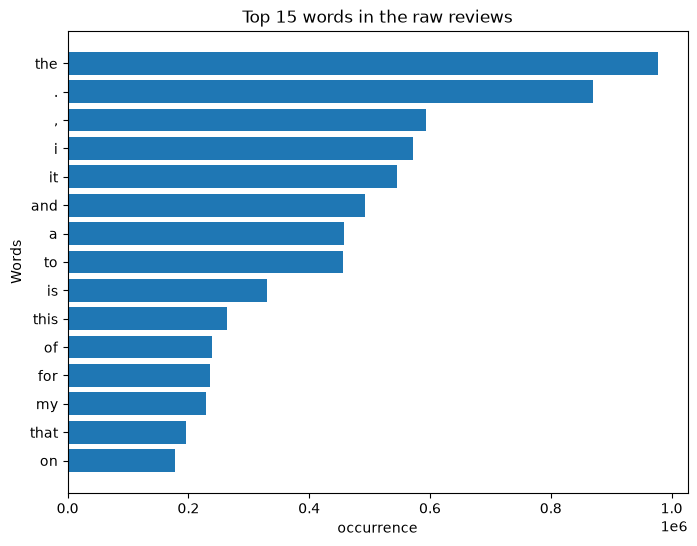

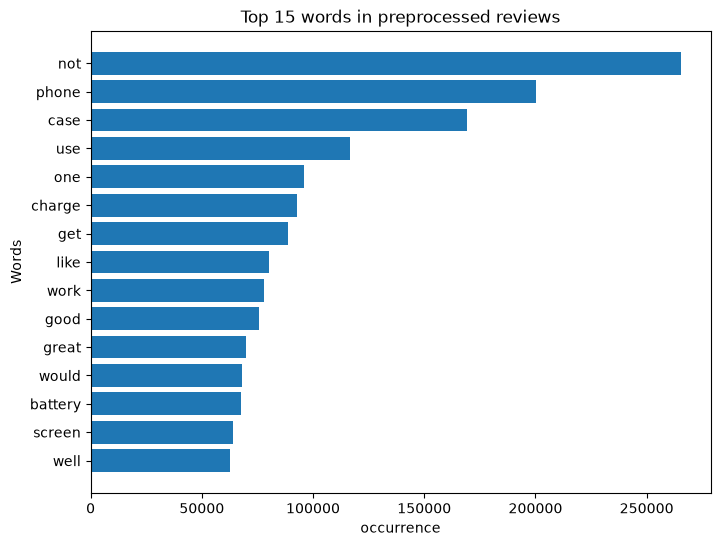

In [8]:
import matplotlib.pyplot as plt

def plot_chart_top_words(most_common_words,title,xlabel, ylabel, n_top_words):
    words, counts = zip(*most_common_words)
    
    plt.figure(figsize=(8, 6))
    plt.barh(words, counts)
    plt.gca().invert_yaxis()
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.show()

plot_chart_top_words(raw_most_common_words, "Top " + str(n_top_words) + " words in the raw reviews", "occurrence", "Words", n_top_words )
plot_chart_top_words(preprocessed_most_common_words, "Top " + str(n_top_words) + " words in preprocessed reviews", "occurrence", "Words", n_top_words )